# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


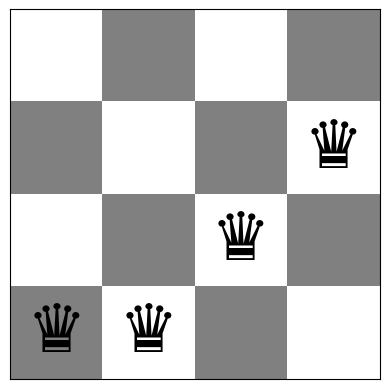

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


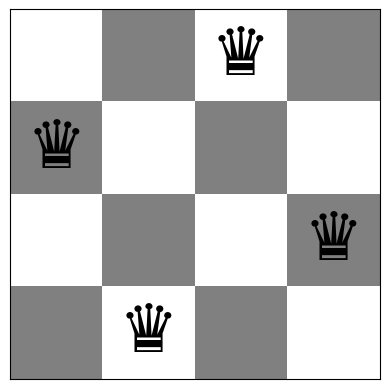

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

### Hàm hỗ trợ

Trạng thái là vector `board` (mỗi cột đúng một quân hậu). Một nước đi cục bộ là đổi hàng của một quân hậu trong cột của nó, nên mỗi trạng thái có $n(n-1)$ láng giềng. Biến đếm `eval_count` ghi lại số lần gọi hàm mục tiêu để so sánh chi phí giữa các thuật toán.

In [ ]:
import math, time

# Bộ đếm số lần gọi hàm mục tiêu conflicts() để so sánh chi phí tính toán
eval_count = 0
def f(board):
    """Hàm mục tiêu có đếm số lần đánh giá."""
    global eval_count
    eval_count += 1
    return conflicts(board)

def all_moves(n):
    """Mọi nước đi cục bộ: (cột, hàng mới). Có n*(n-1) nước đi."""
    return [(c, r) for c in range(n) for r in range(n)]

def apply_move(board, col, row):
    new = board.copy()
    new[col] = row
    return new


### Cài đặt

Mỗi vòng lặp đánh giá toàn bộ $n(n-1)$ láng giềng, chọn nước giảm xung đột nhiều nhất (hòa thì chọn ngẫu nhiên). Dừng khi không có láng giềng nào **tốt hơn hẳn** hiện tại hoặc khi $f=0$.

In [ ]:
def steepest_ascent(board, max_steps=1000):
    """Steepest-ascent HC: xét toàn bộ lân cận, chọn nước giảm xung đột nhiều nhất.
    Dừng khi không có lân cận nào tốt hơn (cực trị cục bộ). Hòa thì chọn ngẫu nhiên."""
    board = np.array(board)
    n = len(board)
    cur = f(board)
    history = [cur]
    for step in range(max_steps):
        best_val, best_moves = cur, []
        for c in range(n):
            for r in range(n):
                if r == board[c]:
                    continue
                val = f(apply_move(board, c, r))
                if val < best_val:
                    best_val, best_moves = val, [(c, r)]
                elif val == best_val and best_moves:
                    best_moves.append((c, r))
        if not best_moves:          # không có bước cải thiện -> dừng
            break
        c, r = best_moves[np.random.randint(len(best_moves))]
        board[c] = r
        cur = best_val
        history.append(cur)
        if cur == 0:
            break
    return board, cur, history


Ban đầu: [7 3 6 5 4 4 0 1] f = 9
Kết thúc: [7 3 7 2 4 6 0 5] f = 1 | số bước: 4 | số lần đánh giá: 281
Board with 1 conflicts.


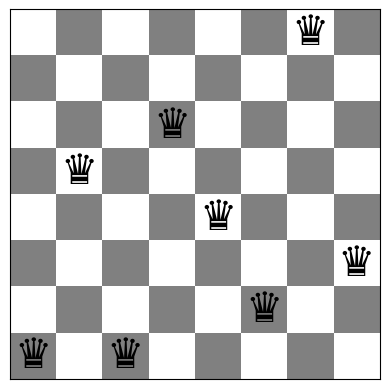

In [7]:
np.random.seed(1234)
eval_count = 0
b0 = random_board(8)
print("Ban đầu:", b0, "f =", conflicts(b0))
b, val, hist = steepest_ascent(b0)
print("Kết thúc:", b, "f =", val, "| số bước:", len(hist) - 1, "| số lần đánh giá:", eval_count)
show_board(b, fontsize=30)

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

### Cài đặt

Giống Task 1 nhưng thay vì chọn nước tốt nhất, thuật toán gom **mọi** nước làm giảm $f$ rồi chọn ngẫu nhiên một nước. Mỗi vòng vẫn tốn $n(n-1)$ lần đánh giá.

In [8]:
def stochastic_hc_all_moves(board, max_steps=1000):
    """Stochastic HC kém hiệu quả: liệt kê MỌI nước cải thiện rồi chọn ngẫu nhiên một nước."""
    board = np.array(board)
    n = len(board)
    cur = f(board)
    history = [cur]
    for step in range(max_steps):
        improving = []
        for c in range(n):
            for r in range(n):
                if r == board[c]:
                    continue
                if f(apply_move(board, c, r)) < cur:
                    improving.append((c, r))
        if not improving:
            break
        c, r = improving[np.random.randint(len(improving))]
        board[c] = r
        cur = conflicts(board)      # giá trị mới (không tính vào bộ đếm, đã biết từ vòng quét)
        history.append(cur)
        if cur == 0:
            break
    return board, cur, history


In [9]:
np.random.seed(1234)
eval_count = 0
b0 = random_board(8)
b, val, hist = stochastic_hc_all_moves(b0)
print("Kết thúc:", b, "f =", val, "| số bước:", len(hist) - 1, "| số lần đánh giá:", eval_count)

Kết thúc: [7 2 0 5 1 4 6 3] f = 0 | số bước: 6 | số lần đánh giá: 337


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

### Cài đặt và chọn ngưỡng dừng

Mỗi lần thử chỉ sinh một láng giềng ngẫu nhiên (cột ngẫu nhiên, hàng mới ngẫu nhiên khác hàng hiện tại), nhận ngay nếu giảm $f$. Ngưỡng dừng $x$ là số lần thử liên tiếp không cải thiện. Vì lấy mẫu có hoàn lại từ $N=n(n-1)$ nước, xác suất một nước cụ thể chưa được thử sau $x$ lần xấp xỉ $e^{-x/N}$. Chọn $x = N(\ln N + 2)$ thì số nước bị bỏ sót kỳ vọng chỉ khoảng $e^{-2} \approx 0.14$, tức hầu như đã thử hết láng giềng trước khi kết luận là cực trị cục bộ. Với $n=8$: $N=56$, $x=\lceil 56(\ln 56+2)\rceil=338$.

In [10]:
def stochastic_hc_first_choice(board, patience=None, max_iter=100000, operator=None):
    """First-choice (Stochastic HC hiệu quả): sinh MỘT lân cận ngẫu nhiên, nhận ngay nếu tốt hơn.
    Dừng khi `patience` lần thử liên tiếp không cải thiện, hoặc hết ngân sách max_iter.

    `operator` là tham số cuối, mặc định None:
      - None: hành vi cũ, chọn đều (cột ngẫu nhiên, hàng ngẫu nhiên khác hàng hiện tại), N = n(n-1).
      - Ngược lại: hàm op(board) trả về apply(board) hoặc None. op có thuộc tính op.N
        = số nước đi hợp lệ của toán tử trên bàn cờ hiện tại, để suy ra
        patience = ceil(N(ln N + 2)). op(board) trả về None <=> op.N == 0.
    """
    board = np.array(board)
    n = len(board)
    if operator is None:
        N = n * (n - 1)                 # số lân cận
    else:
        operator(board)                 # gọi trước để op cập nhật op.N theo bàn cờ hiện tại
        N = operator.N
    cur = f(board)
    history = [cur]
    if cur == 0:                        # đã là nghiệm -> không mất bước nào
        return board, cur, history
    if N == 0:
        # Không còn nước đi hợp lệ nào (ví dụ swap trên bàn cờ mọi hàng bằng nhau):
        # đây là điểm dừng HỢP LỆ, không phải dừng sớm do lỗi. Dừng ngay để tránh log(0).
        return board, cur, history
    if patience is None:
        # Lấy mẫu có hoàn lại: xác suất một nước cụ thể chưa được thử sau x lần là (1-1/N)^x ~ e^(-x/N).
        # Chọn x = N*(ln N + 2) => kỳ vọng số nước bỏ sót ~ N*e^(-(ln N + 2)) = e^-2 ~ 0.14.
        patience = math.ceil(N * (math.log(N) + 2))
    fails = 0
    for it in range(max_iter):
        if operator is None:
            c = np.random.randint(n)
            r = np.random.randint(n - 1)
            if r >= board[c]:           # bỏ qua hàng hiện tại: chọn đều trong n-1 hàng còn lại
                r += 1
            new_board = apply_move(board, c, r)
        else:
            apply = operator(board)
            if apply is None:           # tương đương op.N == 0: không còn nước đi -> dừng
                break
            new_board = apply(board)
        val = f(new_board)
        if val < cur:
            board = new_board
            cur = val
            fails = 0
        else:
            fails += 1
        history.append(cur)
        if cur == 0 or fails >= patience:
            break
    return board, cur, history

In [11]:
np.random.seed(1234)
eval_count = 0
b0 = random_board(8)
b, val, hist = stochastic_hc_first_choice(b0)
print("Kết thúc:", b, "f =", val, "| số lần thử:", len(hist) - 1, "| số lần đánh giá:", eval_count)

Kết thúc: [1 3 5 7 4 6 0 2] f = 1 | số lần thử: 388 | số lần đánh giá: 389


### So sánh ba biến thể (100 lần chạy mỗi cấu hình, seed cố định)

In [12]:
import pandas as pd

def benchmark(algo, n, runs=100, seed=0):
    """Chạy `runs` lần từ các bàn cờ ngẫu nhiên; trả về số liệu trung bình."""
    global eval_count
    np.random.seed(seed)
    rows = []
    for _ in range(runs):
        b0 = random_board(n)
        eval_count = 0
        t0 = time.perf_counter()
        _, val, hist = algo(b0)
        dt = (time.perf_counter() - t0) * 1000
        rows.append((len(hist) - 1, eval_count, val, dt, val == 0))
    r = np.array(rows, dtype=float)
    return {"Vòng lặp TB": r[:, 0].mean(), "Số lần đánh giá TB": r[:, 1].mean(),
            "f cuối TB": r[:, 2].mean(), "Thời gian TB (ms)": r[:, 3].mean(),
            "Tỉ lệ thành công (%)": 100 * r[:, 4].mean()}

algos = {"Steepest-ascent": steepest_ascent,
         "Stochastic (all moves)": stochastic_hc_all_moves,
         "Stochastic (first-choice)": stochastic_hc_first_choice}
table = []
for n in (4, 8):
    for name, a in algos.items():
        table.append({"Thuật toán": name, "n": n, **benchmark(a, n)})
pd.DataFrame(table).round(2)

,Thuật toán,n,Vòng lặp TB,Số lần đánh giá TB,f cuối TB,Thời gian TB (ms),Tỉ lệ thành công (%)
0,Steepest-ascent,4,1.53,25.60,0.56,0.45,49.0
1,Stochastic (all moves),4,1.75,30.04,0.86,0.54,33.0
2,Stochastic (first-choice),4,50.18,51.18,0.85,1.64,26.0
3,Steepest-ascent,8,3.13,225.56,1.30,6.26,12.0
4,Stochastic (all moves),8,5.30,344.84,1.20,5.82,16.0
5,Stochastic (first-choice),8,333.86,334.86,1.25,6.89,21.0


### Nhận xét (Task 1-3)

- **Chất lượng:** cả ba biến thể đều dễ kẹt ở cực trị cục bộ, tỉ lệ tìm được $f=0$ chỉ khoảng 12-21% với $n=8$ (cao hơn, 26-49%, với $n=4$). Ngoại lệ nhỏ giữa các biến thể chủ yếu do ngẫu nhiên, nên cần nhiều lần chạy và Random Restart (Task 4).
- **Chi phí theo vòng lặp:** Steepest-ascent và Stochastic (all moves) đều đánh giá đủ $n(n-1)$ láng giềng mỗi bước, nên số lần gọi `conflicts()` tăng nhanh theo $n$. Stochastic (all moves) còn phải gom danh sách nước tốt nên chậm hơn Steepest-ascent.
- **First-choice:** mỗi lần thử chỉ tốn một lần đánh giá, nhưng cần rất nhiều lần thử vì phải tự phát hiện cực trị cục bộ bằng ngưỡng `patience`. Ở $n=8$ tổng số lần đánh giá xấp xỉ biến thể all-moves, vì phần lớn chi phí nằm ở các lần thử thất bại cuối cùng. Lợi thế của first-choice rõ hơn khi số láng giềng rất lớn và các bước cải thiện thường gặp.
- **Đánh đổi:** biến thể chọn kỹ (steepest) cho mỗi bước tốt nhưng đắt, biến thể ngẫu nhiên rẻ mỗi bước nhưng cần nhiều bước và ngưỡng dừng; không biến thể nào đảm bảo tìm được nghiệm toàn cục.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Steepest-ascent | best conflicts = 0 | {'Số lần restart': 2, 'Tổng số bước': 5, 'Tổng số đánh giá': 338}
Board with 0 conflicts.


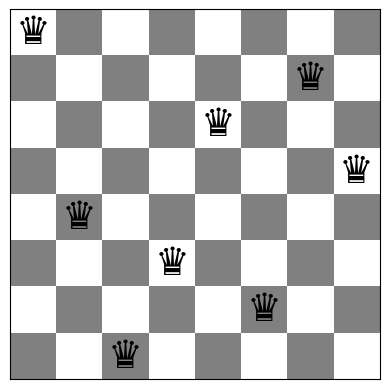

Stochastic (all moves) | best conflicts = 0 | {'Số lần restart': 5, 'Tổng số bước': 27, 'Tổng số đánh giá': 1741}
Board with 0 conflicts.


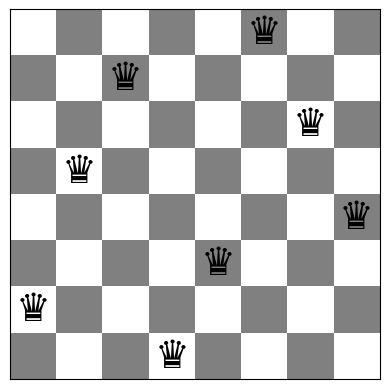

Stochastic (first-choice) | best conflicts = 0 | {'Số lần restart': 1, 'Tổng số bước': 69, 'Tổng số đánh giá': 70}
Board with 0 conflicts.


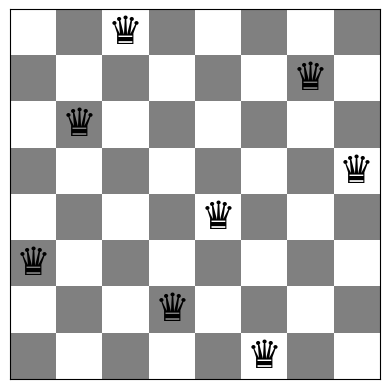

,Thuật toán,Xung đột tốt nhất,Số lần restart,Tổng số bước,Tổng số đánh giá
0,Steepest-ascent,0,2,5,338
1,Stochastic (all moves),0,5,27,1741
2,Stochastic (first-choice),0,1,69,70


In [13]:
def random_restart(algo, n, max_restarts=100):
    """Chạy HC nhiều lần từ bàn cờ ngẫu nhiên; trả nghiệm tốt nhất và thống kê."""
    global eval_count
    best_board, best_val = None, float("inf")
    total_evals, total_steps = 0, 0
    restarts_used = 0
    for restart in range(max_restarts):
        start = random_board(n)
        eval_count = 0
        board, val, history = algo(start)
        total_evals += eval_count
        total_steps += len(history) - 1
        restarts_used += 1
        if val < best_val:
            best_board, best_val = np.array(board).copy(), val
        if best_val == 0:
            break
    return best_board, best_val, {
        "Số lần restart": restarts_used,
        "Tổng số bước": total_steps,
        "Tổng số đánh giá": total_evals
    }

# Thử cả ba biến thể HC, cùng kích thước n=8 và giới hạn 100 lần restart.
np.random.seed(2025)
restart_results = []
for name, algo in [
    ("Steepest-ascent", steepest_ascent),
    ("Stochastic (all moves)", stochastic_hc_all_moves),
    ("Stochastic (first-choice)", stochastic_hc_first_choice)
]:
    board, value, stats = random_restart(algo, n=8, max_restarts=100)
    restart_results.append({"Thuật toán": name, "Xung đột tốt nhất": value, **stats})
    print(name, "| best conflicts =", value, "|", stats)
    if value == 0:
        show_board(board, fontsize=28)
pd.DataFrame(restart_results)

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

### Cài đặt và lựa chọn lịch làm nguội

Mỗi vòng lặp sinh **một** láng giềng ngẫu nhiên (đổi hàng của một quân hậu). Nước đi được nhận nếu
nó tốt hơn, hoặc nếu nó xấu hơn nhưng vẫn được nhận với xác suất

$$P(\text{nhận}) = \exp\left(-\frac{\Delta}{T}\right), \qquad \Delta = f(\text{mới}) - f(\text{hiện tại}) \ge 0 .$$

$T$ giảm dần theo **lịch làm nguội**. Ba lịch được cài đặt:

| Lịch | Công thức $T(t)$ | Đặc điểm |
|---|---|---|
| `geometric` (exponential) | $\max(T_{\min},\, T_0\,\alpha^{\,t-1})$ | giảm theo cấp số nhân, chuẩn mực, nguội nhanh |
| `linear` | $\max(T_{\min},\, T_0(1-(t-1)/t_{\text{cool}}))$ | giảm đều theo thời gian |
| `logarithmic` | $\max(T_{\min},\, T_0/(1+\ln t))$ | giảm rất chậm, còn "nóng" suốt ngân sách lặp |

Tham số: $T_0 = 8$ trong hình minh họa (bàn cờ 8 hàng có tối đa khoảng 28 xung đột, nên $T_0$ vài đơn
vị là đủ để chấp nhận bước xấu lúc đầu) và $T_0 = 10$ (giá trị mặc định của hàm) trong bảng 100 lượt
chạy; $T_{\min} = 0.01$ (dưới ngưỡng này thuật toán gần như chỉ leo dốc); $\alpha = 0.995$–$0.997$ với
`geometric`; $t_{\text{cool}} = 3000$–$5000$ với `linear`; `max_iter = 20000`.

Lịch **logarithmic** được thêm vào để minh họa mặt trái: về lý thuyết nó là lịch hội tụ chậm nhất (tốt
cho SA "đúng nghĩa"), nhưng với ngân sách lặp hữu hạn nó vẫn còn ở nhiệt độ cao lúc kết thúc, nên
nghiệm cuối ít ổn định hơn.

In [14]:
def simulated_annealing(board, schedule="geometric", T0=10.0, Tmin=0.01,
                        alpha=0.995, cooling_steps=5000, max_iter=20000):
    """Simulated annealing cho n-Queens với 3 lịch làm nguội.

    schedule = "geometric"   -> T(t) = max(Tmin, T0 * alpha**(t-1))
             = "linear"      -> T(t) = max(Tmin, T0 * (1 - (t-1)/cooling_steps))
             = "logarithmic" -> T(t) = max(Tmin, T0 / (1 + ln t))

    Trả về (bàn cờ tốt nhất, số xung đột tốt nhất, lịch sử xung đột tốt nhất theo lần lặp).
    """
    board = np.array(board, dtype=int).copy()
    n = len(board)
    current = f(board)
    best_board, best_val = board.copy(), current
    history = [current]
    for t in range(1, max_iter + 1):
        if current == 0:                # đã tìm thấy nghiệm -> dừng sớm
            break
        # một láng giềng ngẫu nhiên: đổi hàng của một quân hậu (hàng mới phải khác hàng cũ)
        col = np.random.randint(n)
        row = np.random.randint(n - 1)
        if row >= board[col]:
            row += 1
        candidate = apply_move(board, col, row)
        candidate_val = f(candidate)

        if schedule == "geometric":
            temperature = max(Tmin, T0 * alpha ** (t - 1))
        elif schedule == "linear":
            temperature = max(Tmin, T0 * (1 - (t - 1) / cooling_steps))
        elif schedule == "logarithmic":
            temperature = max(Tmin, T0 / (1.0 + np.log(t)))
        else:
            raise ValueError("schedule must be 'geometric', 'linear' or 'logarithmic'")

        delta = candidate_val - current
        # nhận nước tốt hơn, hoặc nước xấu hơn với xác suất exp(-delta/T)
        if delta <= 0 or np.random.random() < np.exp(-delta / max(temperature, 1e-12)):
            board, current = candidate, candidate_val
        if current < best_val:
            best_board, best_val = board.copy(), current
        history.append(best_val)
    return best_board, best_val, history

Bàn cờ bắt đầu: [6 6 2 6 4 0 3 3] | xung đột: 6


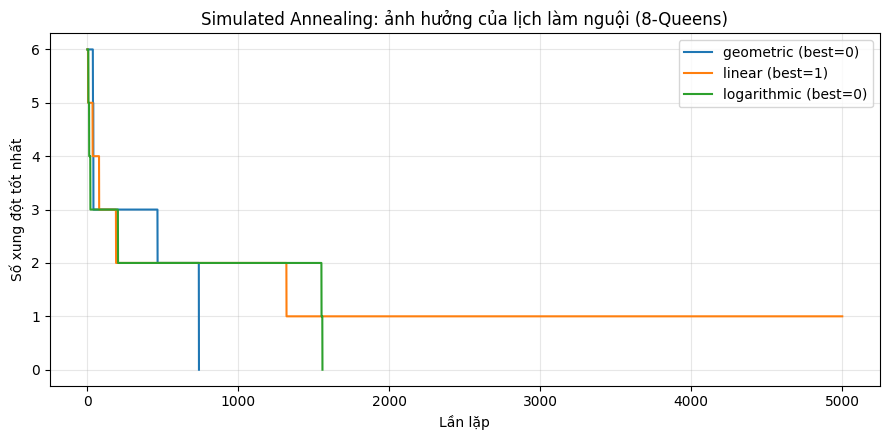

Lịch geometric: xung đột tốt nhất = 0, số vòng lặp = 739
Lịch linear: xung đột tốt nhất = 1, số vòng lặp = 5000
Lịch logarithmic: xung đột tốt nhất = 0, số vòng lặp = 1557


,Lịch làm nguội,n,Thời gian TB (ms),Xung đột TB,Tỉ lệ tối ưu (%)
0,geometric,4,2.00,0.00,100.0
1,linear,4,1.95,0.00,100.0
2,logarithmic,4,1.95,0.00,100.0
3,geometric,8,45.70,0.02,98.0
4,linear,8,138.54,0.01,99.0
5,logarithmic,8,198.73,0.02,98.0


In [15]:
# ---- Biểu đồ 1: số xung đột tốt nhất theo lần lặp, cho từng lịch làm nguội (n = 8) ----
# Cùng một bàn cờ bắt đầu cho cả ba lịch để so sánh trực tiếp đường hội tụ.
np.random.seed(2025)
start_board = random_board(8)
print("Bàn cờ bắt đầu:", start_board, "| xung đột:", conflicts(start_board))

fig, ax = plt.subplots(figsize=(9, 4.5))
schedule_runs = {}
for schedule in ("geometric", "linear", "logarithmic"):
    result_board, result_val, hist = simulated_annealing(
        start_board, schedule=schedule, T0=8.0, alpha=0.997,
        cooling_steps=3000, max_iter=5000
    )
    schedule_runs[schedule] = (result_board, result_val, hist)
    ax.plot(hist, label=f"{schedule} (best={result_val})", linewidth=1.5)
ax.set(title="Simulated Annealing: ảnh hưởng của lịch làm nguội (8-Queens)",
       xlabel="Lần lặp", ylabel="Số xung đột tốt nhất")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

for schedule, (_, val, hist) in schedule_runs.items():
    print(f"Lịch {schedule}: xung đột tốt nhất = {val}, số vòng lặp = {len(hist)-1}")

# ---- 100 lượt chạy SA cho mỗi lịch, tại n = 4 và n = 8 ----
# Cùng seed cho mọi cấu hình của cùng một kích thước -> cùng tập bàn cờ bắt đầu.
SA_RUNS = 100
sa_rows = []
for n in (4, 8):
    for schedule, params in [("geometric", {"alpha": 0.995}),
                             ("linear", {"cooling_steps": 5000}),
                             ("logarithmic", {})]:
        np.random.seed(3000 + n)
        vals, times, success = [], [], []
        for _ in range(SA_RUNS):
            board0 = random_board(n)
            t0 = time.perf_counter()
            _, val, _ = simulated_annealing(board0, schedule=schedule,
                                           max_iter=20000, **params)
            times.append((time.perf_counter() - t0) * 1000)
            vals.append(val)
            success.append(val == 0)
        sa_rows.append({"Lịch làm nguội": schedule, "n": n,
                        "Thời gian TB (ms)": np.mean(times),
                        "Xung đột TB": np.mean(vals),
                        "Tỉ lệ tối ưu (%)": 100 * np.mean(success)})
sa_table = pd.DataFrame(sa_rows)
display(sa_table.round(2))

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [16]:
# Task 6 — Comparison: tối thiểu 100 lần chạy cho mỗi thuật toán và kích thước.
# Để công bằng, mỗi lần chạy bắt đầu từ bàn cờ ngẫu nhiên mới; thời gian được đo bằng perf_counter.
def benchmark_algorithms(algorithms, sizes=(4, 8), runs=100, seed=600):
    global eval_count
    rows = []
    for n in sizes:
        for name, algo in algorithms.items():
            np.random.seed(seed + n)
            run_times, final_vals, success_rates, evals = [], [], [], []
            for _ in range(runs):
                start = random_board(n)
                eval_count = 0
                t0 = time.perf_counter()
                _, val, hist = algo(start)
                run_times.append(time.perf_counter() - t0)
                final_vals.append(val)
                success_rates.append(val == 0)
                evals.append(eval_count)
            rows.append({
                "Algorithm": name, "Board size": n,
                "Avg. run time (ms)": 1000*np.mean(run_times),
                "Avg. conflicts": np.mean(final_vals),
                "Optimal runs (%)": 100*np.mean(success_rates),
                "Avg. objective evaluations": np.mean(evals)
            })
    return pd.DataFrame(rows)

algorithms = {
    "Steepest asc. HC": steepest_ascent,
    "Ineff. Stochastic HC": stochastic_hc_all_moves,
    "Efficient Stochastic HC": stochastic_hc_first_choice,
    "Simulated Annealing": simulated_annealing
}
comparison = benchmark_algorithms(algorithms, sizes=(4, 8), runs=100)
display(comparison.round(3))


,Algorithm,Board size,Avg. run time (ms),Avg. conflicts,Optimal runs (%),Avg. objective evaluations
0,Steepest asc. HC,4,0.245,0.64,44.0,25.96
1,Ineff. Stochastic HC,4,0.305,0.75,37.0,32.08
2,Efficient Stochastic HC,4,0.647,0.79,36.0,45.31
3,Simulated Annealing,4,2.041,0.00,100.0,119.65
4,Steepest asc. HC,8,3.352,1.23,17.0,228.92
5,Ineff. Stochastic HC,8,4.679,1.36,13.0,327.48
6,Efficient Stochastic HC,8,7.459,1.24,16.0,358.29
7,Simulated Annealing,8,36.047,0.02,98.0,1422.72


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

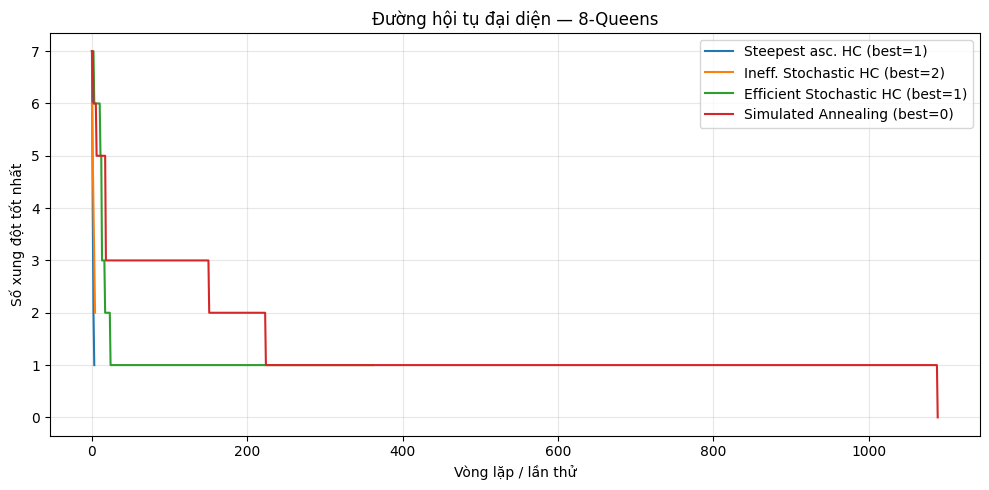

Kết quả đại diện:
- Steepest asc. HC: xung đột tốt nhất = 1; số điểm lịch sử = 4
- Ineff. Stochastic HC: xung đột tốt nhất = 2; số điểm lịch sử = 5
- Efficient Stochastic HC: xung đột tốt nhất = 1; số điểm lịch sử = 363
- Simulated Annealing: xung đột tốt nhất = 0; số điểm lịch sử = 1090

Nhận xét khi đọc đồ thị:
- Steepest-ascent thường giảm nhanh vì khảo sát toàn bộ láng giềng, nhưng dừng ở cực trị cục bộ khi không còn bước tốt hơn.
- Stochastic all-moves cũng chỉ nhận bước cải thiện; đường đi có thể khác do chọn ngẫu nhiên trong các bước tốt.
- First-choice có thể có đoạn nằm ngang dài vì thử nhiều bước không cải thiện trước khi dừng.
- Simulated annealing có thể chấp nhận bước xấu khi nhiệt độ còn cao, giúp thoát bẫy cục bộ; khi nhiệt độ giảm, tiến trình ổn định hơn.
Đây là mô tả xu hướng, không phải bảo đảm cho mọi lần chạy; kết quả thay đổi theo seed và tham số.



In [17]:
# Task 6 — Algorithm convergence: một lần chạy đại diện cho mỗi thuật toán trên 8-Queens.
np.random.seed(808)
representative_histories = {}
for name, algo in algorithms.items():
    _, val, hist = algo(random_board(8))
    representative_histories[name] = (val, hist)

fig, ax = plt.subplots(figsize=(10, 5))
for name, (val, hist) in representative_histories.items():
    ax.plot(hist, label=f"{name} (best={val})", linewidth=1.5)
ax.set(title="Đường hội tụ đại diện — 8-Queens",
       xlabel="Vòng lặp / lần thử", ylabel="Số xung đột tốt nhất")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print("Kết quả đại diện:")
for name, (val, hist) in representative_histories.items():
    print(f"- {name}: xung đột tốt nhất = {val}; số điểm lịch sử = {len(hist)}")

print("""
Nhận xét khi đọc đồ thị:
- Steepest-ascent thường giảm nhanh vì khảo sát toàn bộ láng giềng, nhưng dừng ở cực trị cục bộ khi không còn bước tốt hơn.
- Stochastic all-moves cũng chỉ nhận bước cải thiện; đường đi có thể khác do chọn ngẫu nhiên trong các bước tốt.
- First-choice có thể có đoạn nằm ngang dài vì thử nhiều bước không cải thiện trước khi dừng.
- Simulated annealing có thể chấp nhận bước xấu khi nhiệt độ còn cao, giúp thoát bẫy cục bộ; khi nhiệt độ giảm, tiến trình ổn định hơn.
Đây là mô tả xu hướng, không phải bảo đảm cho mọi lần chạy; kết quả thay đổi theo seed và tham số.
""")


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

,Algorithm,n,Avg. runtime (s)
0,Steepest asc. HC,4,0.00028
1,Efficient Stochastic HC,4,0.00105
2,Simulated Annealing,4,0.00198
3,Steepest asc. HC,8,0.00336
4,Efficient Stochastic HC,8,0.00930
5,Simulated Annealing,8,0.04974
6,Steepest asc. HC,12,0.01329
7,Efficient Stochastic HC,12,0.02614
8,Simulated Annealing,12,0.06343
9,Steepest asc. HC,16,0.04839


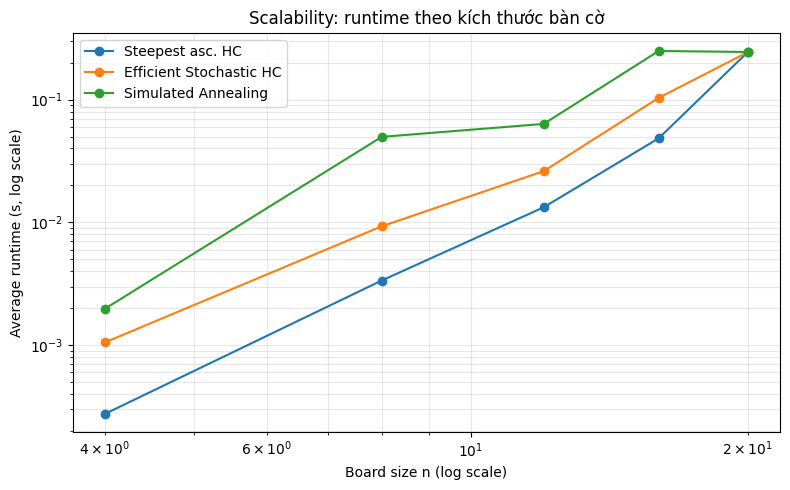

,Algorithm,Empirical exponent k,Approx. trend
0,Steepest asc. HC,4.041,O(n^4.04)
1,Efficient Stochastic HC,3.339,O(n^3.34)
2,Simulated Annealing,3.003,O(n^3.00)



Diễn giải: hệ số k được ước lượng từ một số kích thước nhỏ và các lần chạy ngẫu nhiên,
nên chỉ là xu hướng thực nghiệm, không phải chứng minh độ phức tạp Big-O lý thuyết.
Steepest-ascent đánh giá O(n^2) láng giềng ở mỗi bước; mỗi lần đánh giá conflicts tốn O(n),
nên chi phí mỗi bước xấp xỉ O(n^3). First-choice và simulated annealing đánh giá một láng giềng
mỗi vòng (mỗi lần conflicts tốn O(n)), nhưng tổng số vòng lặp phụ thuộc ngẫu nhiên và lịch dừng.



In [18]:
# Task 6 — Scalability. Đo thời gian trên n=4, 8, 12, 16, 20.
# Dùng ít lượt hơn ở phần này vì đây là khảo sát xu hướng; bảng so sánh chính phía trên vẫn dùng 100 lượt.
def scalability_run(algo, n, runs=5):
    times = []
    for _ in range(runs):
        start = random_board(n)
        t0 = time.perf_counter()
        algo(start)
        times.append(time.perf_counter() - t0)
    return float(np.mean(times))

scalability_algorithms = {
    "Steepest asc. HC": steepest_ascent,
    "Efficient Stochastic HC": stochastic_hc_first_choice,
    "Simulated Annealing": simulated_annealing
}
sizes = [4, 8, 12, 16, 20]
scalability_rows = []
for n in sizes:
    for name, algo in scalability_algorithms.items():
        # Chạy 5 lần cho mỗi điểm; thời gian có thể biến động do thuật toán ngẫu nhiên.
        avg_seconds = scalability_run(algo, n, runs=5)
        scalability_rows.append({"Algorithm": name, "n": n, "Avg. runtime (s)": avg_seconds})
scalability = pd.DataFrame(scalability_rows)
display(scalability.round(5))

fig, ax = plt.subplots(figsize=(8, 5))
for name in scalability_algorithms:
    part = scalability[scalability["Algorithm"] == name]
    ax.loglog(part["n"], part["Avg. runtime (s)"], marker="o", label=name)
ax.set(title="Scalability: runtime theo kích thước bàn cờ",
       xlabel="Board size n (log scale)", ylabel="Average runtime (s, log scale)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Ước lượng số mũ thực nghiệm tỉ lệ runtime ~ n^k bằng hồi quy tuyến tính trên log-log.
complexity_rows = []
for name in scalability_algorithms:
    part = scalability[scalability["Algorithm"] == name]
    x = np.log(part["n"].to_numpy(dtype=float))
    y = np.log(np.maximum(part["Avg. runtime (s)"].to_numpy(dtype=float), 1e-9))
    slope = np.polyfit(x, y, 1)[0]
    complexity_rows.append({"Algorithm": name, "Empirical exponent k": slope,
                            "Approx. trend": f"O(n^{slope:.2f})"})
display(pd.DataFrame(complexity_rows).round(3))

print("""
Diễn giải: hệ số k được ước lượng từ một số kích thước nhỏ và các lần chạy ngẫu nhiên,
nên chỉ là xu hướng thực nghiệm, không phải chứng minh độ phức tạp Big-O lý thuyết.
Steepest-ascent đánh giá O(n^2) láng giềng ở mỗi bước; mỗi lần đánh giá conflicts tốn O(n),
nên chi phí mỗi bước xấp xỉ O(n^3). First-choice và simulated annealing đánh giá một láng giềng
mỗi vòng (mỗi lần conflicts tốn O(n)), nhưng tổng số vòng lặp phụ thuộc ngẫu nhiên và lịch dừng.
""")


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [19]:
# =====================================================================
# Advanced task: các toán tử nước đi cục bộ (local move operators)
#
# Giao diện chung: mỗi toán tử là một factory make_<ten>_operator(rng)
#   -> trả về hàm op(board).
#   op(board) trả về hàm apply(board) -> board mới, hoặc None nếu toán tử
#   KHÔNG có nước đi hợp lệ nào trên bàn cờ đó.
#   op.N = số nước đi PHÂN BIỆT hợp lệ của toán tử trên bàn cờ vừa truyền vào.
#   Vì vậy op(board) trả về None <=> op.N == 0 (điểm dừng hợp lệ).
#   op.N dùng để suy ra patience = ceil(N (ln N + 2)) cho efficient stochastic
#   hill climbing.
# `rng` là numpy Generator, ví dụ np.random.default_rng(seed), để tái lập kết quả.
#
# Mỗi toán tử xây DANH SÁCH các nước hợp lệ rồi lấy mẫu đều một nước, KHÔNG
# dùng vòng lặp thử-và-loại (rejection sampling): vòng lặp đó có thể thất bại
# dù còn nước hợp lệ, làm toán tử trả None sai và thuật toán dừng sớm.
# =====================================================================


def column_conflicts(board, c):
    """Số quân hậu đang tấn công quân ở cột c (chỉ dùng cho toán tử adaptive)."""
    cnt = 0
    for j in range(len(board)):
        if j != c and (board[j] == board[c] or abs(board[j] - board[c]) == abs(j - c)):
            cnt += 1
    return cnt


def make_single_step_operator(rng):
    """Single-step: đổi hàng của MỘT quân hậu đúng +1 hoặc -1.
    Chỉ liệt kê các nước hợp lệ nên không bao giờ ra ngoài bàn cờ."""
    def op(board):
        board = np.asarray(board)
        n = len(board)
        moves = []
        for c in range(n):
            if board[c] > 0:
                moves.append((c, int(board[c]) - 1))
            if board[c] < n - 1:
                moves.append((c, int(board[c]) + 1))
        op.N = len(moves)               # đếm thật: 2n trừ các cột đang ở hàng biên
        if not moves:
            return None
        c, r = moves[int(rng.integers(len(moves)))]

        def apply(b):
            new = np.array(b)
            new[c] = r
            return new
        return apply
    op.N = None
    return op


def make_column_swap_operator(rng):
    """Column swap: hoán đổi hàng của HAI cột KHÁC hàng.
    Chỉ liệt kê các cặp cột có hàng khác nhau, nên op.N phụ thuộc bàn cờ."""
    def op(board):
        board = np.asarray(board)
        n = len(board)
        moves = [(a, b) for a in range(n) for b in range(a + 1, n)
                 if board[a] != board[b]]
        op.N = len(moves)
        if not moves:
            return None
        a, b = moves[int(rng.integers(len(moves)))]

        def apply(bd):
            new = np.array(bd)
            new[a], new[b] = new[b], new[a]
            return new
        return apply
    op.N = None
    return op


def make_dual_queen_operator(rng):
    """Dual-queen: chọn hai cột và đổi hàng của CẢ HAI (hàng mới khác hàng cũ).
    Mọi cặp cột đều hợp lệ; op.N = C(n,2)*(n-1)^2 nước đi phân biệt."""
    def op(board):
        board = np.asarray(board)
        n = len(board)
        if n < 2:
            op.N = 0
            return None
        op.N = math.comb(n, 2) * (n - 1) ** 2
        pairs = [(a, b) for a in range(n) for b in range(a + 1, n)]
        a, b = pairs[int(rng.integers(len(pairs)))]
        ra = int(rng.integers(n - 1))
        if ra >= board[a]:
            ra += 1
        rb = int(rng.integers(n - 1))
        if rb >= board[b]:
            rb += 1

        def apply(bd):
            new = np.array(bd)
            new[a] = ra
            new[b] = rb
            return new
        return apply
    op.N = None
    return op


def make_adaptive_operator(rng, p=0.5, top_k=3):
    """Adaptive: với xác suất p chỉ dùng top_k cột nhiều xung đột nhất (đếm bằng
    column_conflicts); ngược lại dùng toàn bộ cột. Chọn đều một trong ba toán tử
    (single-step, swap, dual) có nước hợp lệ. Nếu nhánh bị giới hạn không có nước,
    quay về tập nước không giới hạn của nhánh đó, nên với n >= 2 không bao giờ
    trả về None. op.N = số nước phân biệt của nhánh dual-queen KHÔNG giới hạn
    (nhánh lớn nhất), không phụ thuộc nhánh vừa được lấy mẫu."""
    def op(board):
        board = np.asarray(board)
        n = len(board)
        if n < 2:
            op.N = 0
            return None
        # adaptive báo N của nhánh lớn nhất (dual-queen không giới hạn): search đọc N một
        # lần từ lần gọi đầu để suy ra patience, nên N không được phụ thuộc nhánh lấy mẫu.
        op.N = math.comb(n, 2) * (n - 1) ** 2
        conf = [column_conflicts(board, c) for c in range(n)]
        top = [int(x) for x in np.argsort(-np.asarray(conf), kind="stable")[:top_k]]
        if len(top) >= 2 and rng.random() < p:
            cols = top
        else:
            cols = list(range(n))

        single = [(c, int(board[c]) + d) for c in cols for d in (-1, 1)
                  if 0 <= int(board[c]) + d <= n - 1]
        if not single:                  # nhánh giới hạn không có nước -> bỏ giới hạn
            single = [(c, int(board[c]) + d) for c in range(n) for d in (-1, 1)
                      if 0 <= int(board[c]) + d <= n - 1]
        swap = [(a, b) for i, a in enumerate(cols) for b in cols[i + 1:]
                if board[a] != board[b]]
        if not swap:
            swap = [(a, b) for a in range(n) for b in range(a + 1, n)
                    if board[a] != board[b]]
        dual = [(a, b) for i, a in enumerate(cols) for b in cols[i + 1:]]
        if not dual:
            dual = [(a, b) for a in range(n) for b in range(a + 1, n)]

        choices = []
        if single:
            choices.append(("single", single))
        if swap:
            choices.append(("swap", swap))
        if dual:
            choices.append(("dual", dual))
        kind, moves = choices[int(rng.integers(len(choices)))]

        if kind == "single":
            c, r = moves[int(rng.integers(len(moves)))]

            def apply(bd):
                new = np.array(bd)
                new[c] = r
                return new
            return apply
        if kind == "swap":
            a, b = moves[int(rng.integers(len(moves)))]

            def apply(bd):
                new = np.array(bd)
                new[a], new[b] = new[b], new[a]
                return new
            return apply
        a, b = moves[int(rng.integers(len(moves)))]
        ra = int(rng.integers(n - 1))
        if ra >= board[a]:
            ra += 1
        rb = int(rng.integers(n - 1))
        if rb >= board[b]:
            rb += 1

        def apply(bd):
            new = np.array(bd)
            new[a] = ra
            new[b] = rb
            return new
        return apply
    op.N = None
    return op

### Giao diện toán tử và ngưỡng dừng `patience`

Mỗi toán tử là một **factory** `make_<tên>_operator(rng)` trả về hàm `op(board)`.

* `op(board)` trả về hàm `apply(board) -> board mới`, hoặc `None` **khi và chỉ khi** toán tử không có nước hợp lệ nào.
* `op.N` là **số nước đi PHÂN BIỆT hợp lệ** của toán tử trên bàn cờ vừa truyền vào; riêng `adaptive`
  báo **cận trên** — số nước của nhánh dual-queen lớn nhất (xem bảng bên dưới).

Vì vậy `op(board)` trả về `None` ⇔ `op.N == 0`. Đó là một điểm dừng **hợp lệ** (cực trị cục bộ theo
toán tử), ví dụ bàn cờ mọi hàng bằng nhau với toán tử column swap.

`stochastic_hc_first_choice` được mở rộng thêm tham số cuối `operator=None`. Khi truyền `operator`, thuật toán
lấy ngay `N = operator.N` và tự suy ra ngưỡng dừng

$$\text{patience} = \lceil N(\ln N + 2) \rceil .$$

Nếu `N == 0`, thuật toán dừng ngay (không gọi `ln 0`). Vì patience lấy từ `operator.N`, đổi toán tử là tự
động đổi ngưỡng dừng, không hard-code. Search chỉ đọc `N` **một lần**, ngay ở lần gọi `op` đầu tiên; vì vậy
adaptive báo `N` của nhánh lớn nhất (dual-queen), không phải nhánh nó lấy mẫu ở lần gọi đó.

| Toán tử | N trên bàn cờ hiện tại |
|---|---|
| single-step (đổi hàng ±1) | số cột đổi được ±1, tối đa $2n$ (tùy bàn cờ) |
| column swap | số cặp cột **khác hàng**, tối đa $\binom{n}{2}$ (tùy bàn cờ) |
| dual-queen (đổi 2 cột, cả 2 hàng) | $\binom{n}{2}(n-1)^2$ (không đổi theo bàn cờ) |
| adaptive | $\binom{n}{2}(n-1)^2$ của nhánh dual-queen lớn nhất (không phụ thuộc nhánh lấy mẫu) |

Mỗi toán tử **liệt kê danh sách nước hợp lệ rồi lấy mẫu đều một nước**, không dùng vòng lặp thử-và-loại. Vòng
lặp thử-và-loại có thể thất bại dù vẫn còn nước hợp lệ, khiến `op` trả `None` sai và thuật toán dừng sớm rồi
bị báo nhầm là đã hội tụ. Với adaptive, nếu nhánh bị giới hạn vào top-k cột không có nước, toán tử quay về tập
nước không giới hạn của nhánh đó; nhờ vậy adaptive luôn có nước khi $n \ge 2$.

`operator=None` giữ nguyên hành vi cũ: cột ngẫu nhiên, hàng ngẫu nhiên khác hàng hiện tại, $N = n(n-1)$.

In [20]:
# Thử nhanh 4 toán tử trên n = 8: mỗi toán tử chạy một lần từ cùng một bàn cờ.
np.random.seed(1234)
b0 = random_board(8)
print("Bàn cờ ban đầu:", b0, "| xung đột:", conflicts(b0))
for name, factory in [("Single-step", make_single_step_operator),
                      ("Column swap", make_column_swap_operator),
                      ("Dual-queen", make_dual_queen_operator),
                      ("Adaptive", make_adaptive_operator)]:
    np.random.seed(1234)
    eval_count = 0
    op = factory(np.random.default_rng(1234))
    # Search đọc op.N ngay ở lần gọi op ĐẦU TIÊN rồi tự suy ra patience. Một toán tử
    # "nhìn trước" cùng seed, gọi đúng một lần trên b0, cho biết N thật đã dùng mà
    # không làm đổi lần chạy (toán tử nhìn trước không được đưa vào search).
    op_peek = factory(np.random.default_rng(1234))
    op_peek(b0)
    N_used = op_peek.N
    patience_used = math.ceil(N_used * (math.log(N_used) + 2)) if N_used else 0
    b, val, hist = stochastic_hc_first_choice(b0, operator=op)
    print(f"{name:12s} | N = {N_used:6d} | patience = {patience_used:6d} | "
          f"vòng lặp = {len(hist)-1:5d} | f cuối = {val} | đánh giá = {eval_count}")

Bàn cờ ban đầu: [7 3 6 5 4 4 0 1] | xung đột: 9
Single-step  | N =     14 | patience =     65 | vòng lặp =    66 | f cuối = 6 | đánh giá = 67
Column swap  | N =     27 | patience =    143 | vòng lặp =   169 | f cuối = 2 | đánh giá = 170
Dual-queen   | N =   1372 | patience =  12656 | vòng lặp =  1422 | f cuối = 0 | đánh giá = 1423
Adaptive     | N =   1372 | patience =  12656 | vòng lặp = 14160 | f cuối = 1 | đánh giá = 14161


### Thực nghiệm trên 8-Queens và 12-Queens

Với mỗi toán tử: chạy **efficient stochastic hill climbing 100 lần**, mỗi lần bắt đầu từ `random_board(n)`,
seed cố định cho từng cấu hình (`np.random.seed(seed)` cho bàn cờ và `np.random.default_rng(seed)` cho toán tử).

Mỗi lần chạy ghi lại: số vòng lặp, số lần đánh giá hàm mục tiêu `eval_count`, số xung đột cuối, thời gian
(ms), có thành công hay không ($f = 0$), và cả `history` để vẽ đường hội tụ.

In [21]:
# Thực nghiệm: efficient stochastic HC với 4 toán tử, n = 8 và n = 12.
OPERATORS = {"Single-step": make_single_step_operator,
             "Column swap": make_column_swap_operator,
             "Dual-queen": make_dual_queen_operator,
             "Adaptive": make_adaptive_operator}

def run_operator(factory, n, runs, seed):
    """Chạy `runs` lần stochastic HC với một toán tử; trả về số liệu từng lần chạy."""
    global eval_count
    np.random.seed(seed)                    # cho random_board
    rng = np.random.default_rng(seed)       # cho toán tử
    iters, evals, finals, times, success, histories = [], [], [], [], [], []
    for _ in range(runs):
        b0 = random_board(n)
        eval_count = 0
        op = factory(rng)
        t0 = time.perf_counter()
        _, val, hist = stochastic_hc_first_choice(b0, operator=op)
        dt = (time.perf_counter() - t0) * 1000
        iters.append(len(hist) - 1)
        evals.append(eval_count)
        finals.append(val)
        times.append(dt)
        success.append(val == 0)
        histories.append(hist)
    return {"iters": np.array(iters, float), "evals": np.array(evals, float),
            "finals": np.array(finals, float), "times": np.array(times, float),
            "success": np.array(success, bool), "histories": histories}

RUNS = {8: 100, 12: 100}
RESULTS = {}
for n in (8, 12):
    for name, factory in OPERATORS.items():
        RESULTS[(n, name)] = run_operator(factory, n, RUNS[n], seed=1000 + n)

rows = []
for n in (8, 12):
    for name in OPERATORS:
        r = RESULTS[(n, name)]
        ok = r["times"][r["success"]]
        rows.append({"Toán tử": name, "n": n, "Số lần chạy": RUNS[n],
                     "Vòng lặp TB": r["iters"].mean(),
                     "Số đánh giá TB": r["evals"].mean(),
                     "f cuối TB": r["finals"].mean(),
                     "Thời gian TB (ms)": r["times"].mean(),
                     "TG khi thành công (ms)": ok.mean() if len(ok) else float("nan"),
                     "Tỉ lệ thành công (%)": 100 * r["success"].mean()})
summary_ops = pd.DataFrame(rows)
summary_ops.round(2)

,Toán tử,n,Số lần chạy,Vòng lặp TB,Số đánh giá TB,f cuối TB,Thời gian TB (ms),TG khi thành công (ms),Tỉ lệ thành công (%)
0,Single-step,8,100,87.16,88.16,3.42,2.42,0.51,1.0
1,Column swap,8,100,151.66,152.66,4.47,4.36,NaN,0.0
2,Dual-queen,8,100,9664.73,9665.73,0.71,297.55,38.46,30.0
3,Adaptive,8,100,11274.16,11275.16,0.85,1357.80,175.90,19.0
4,Single-step,12,100,158.32,159.32,5.26,12.37,NaN,0.0
5,Column swap,12,100,429.78,430.78,6.37,35.15,NaN,0.0
6,Dual-queen,12,100,72711.76,72712.76,0.87,2976.59,374.58,22.0
7,Adaptive,12,100,80063.78,80064.78,0.89,16102.23,6080.60,18.0


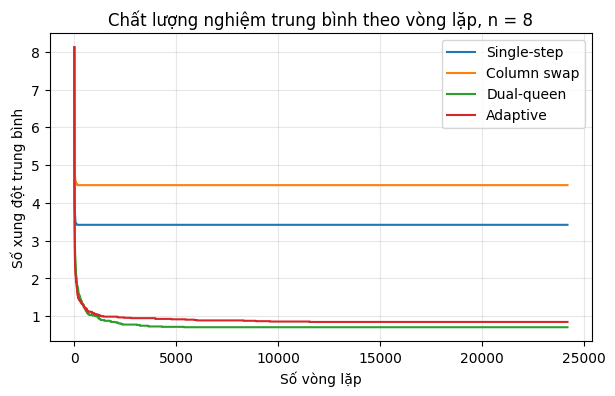

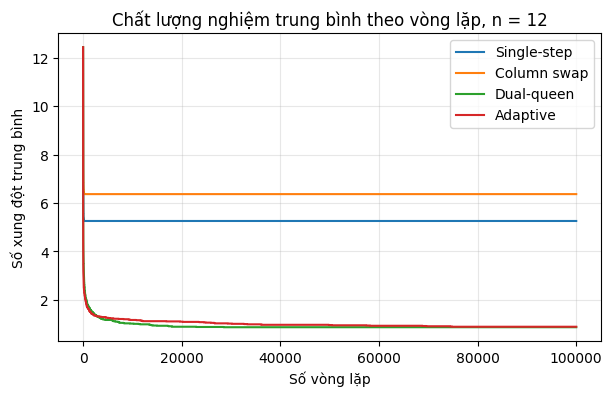

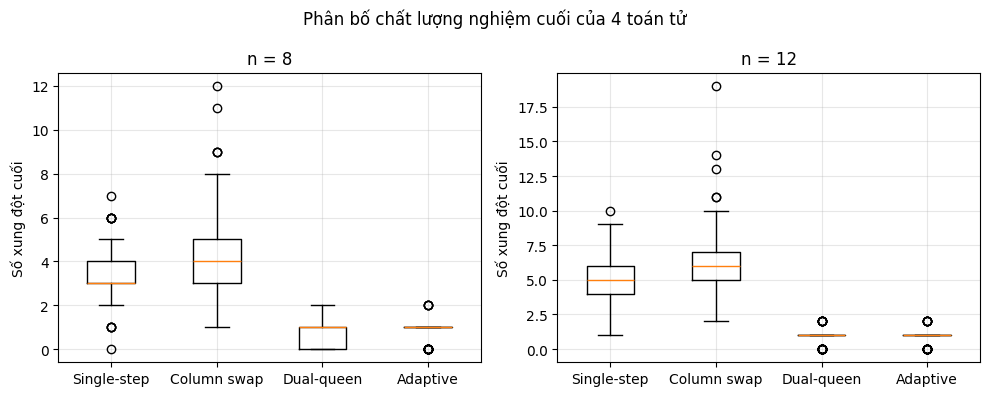

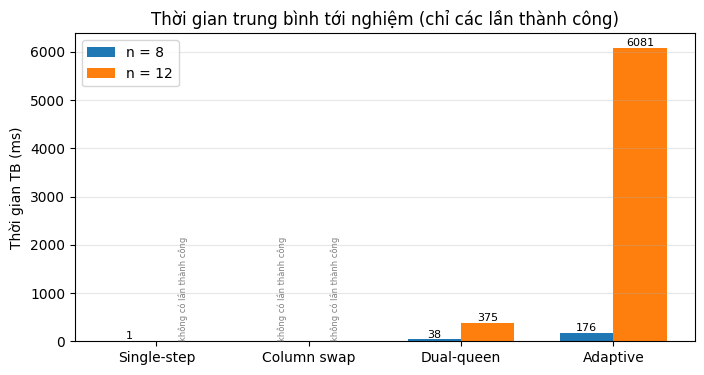

In [22]:
COLORS = {"Single-step": "tab:blue", "Column swap": "tab:orange",
          "Dual-queen": "tab:green", "Adaptive": "tab:red"}

def pad_to(hist, length):
    """Các history có độ dài khác nhau -> kéo dài bằng giá trị cuối (quy ước đã chọn)."""
    return np.array(list(hist) + [hist[-1]] * (length - len(hist)), dtype=float)

# (1) Chất lượng trung bình theo vòng lặp (mỗi board size một hình).
for n in (8, 12):
    L = max(len(h) for name in OPERATORS for h in RESULTS[(n, name)]["histories"])
    plt.figure(figsize=(7, 4))
    for name in OPERATORS:
        curves = np.array([pad_to(h, L) for h in RESULTS[(n, name)]["histories"]])
        plt.plot(curves.mean(axis=0), label=name, color=COLORS[name])
    plt.xlabel("Số vòng lặp"); plt.ylabel("Số xung đột trung bình")
    plt.title(f"Chất lượng nghiệm trung bình theo vòng lặp, n = {n}")
    plt.legend(); plt.grid(alpha=0.3); plt.show()

# (2) Phân bố chất lượng nghiệm cuối.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, n in zip(axes, (8, 12)):
    ax.boxplot([RESULTS[(n, name)]["finals"] for name in OPERATORS],
               tick_labels=list(OPERATORS))
    ax.set_title(f"n = {n}"); ax.set_ylabel("Số xung đột cuối"); ax.grid(alpha=0.3)
fig.suptitle("Phân bố chất lượng nghiệm cuối của 4 toán tử")
plt.tight_layout(); plt.show()

# (3) Thời gian trung bình tới nghiệm, CHỈ tính các lần thành công.
# Cấu hình không có lần thành công nào thì KHÔNG vẽ cột (nếu vẽ 0 ms sẽ gây hiểu
# nhầm thành "rất nhanh"), chỉ ghi chú "không có lần thành công".
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.35
xs = np.arange(len(OPERATORS))
for k, n in enumerate((8, 12)):
    first = True
    for j, name in enumerate(OPERATORS):
        ok = RESULTS[(n, name)]["times"][RESULTS[(n, name)]["success"]]
        x = j + (k - 0.5) * w
        if len(ok) == 0:
            ax.text(x, 0, "không có lần thành công", ha="center", va="bottom",
                    fontsize=6, rotation=90, color="gray")
            continue
        v = float(ok.mean())
        ax.bar(x, v, w, color=("tab:blue" if k == 0 else "tab:orange"),
               label=(f"n = {n}" if first else None))
        ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8)
        first = False
ax.set_xticks(xs); ax.set_xticklabels(list(OPERATORS))
ax.set_ylabel("Thời gian TB (ms)")
ax.set_title("Thời gian trung bình tới nghiệm (chỉ các lần thành công)")
ax.legend(); ax.grid(alpha=0.3, axis="y"); plt.show()

### Nhận xét (Advanced task)

Số liệu lấy trực tiếp từ bảng và các hình ở trên (100 lần chạy mỗi cấu hình).

* **Single-step** rẻ nhất: 1.25 ms mỗi lần chạy ở n = 8 và 2.51 ms ở n = 12, chỉ khoảng 88 và 159 lần đánh giá.
  Nhưng lân cận quá nhỏ nên gần như luôn kẹt: **1%** thành công ở n = 8 và **0%** ở n = 12; f cuối trung bình
  3.42 và 5.26. Một quân hậu chỉ nhích một hàng, không đủ để thoát khỏi thế cục bộ.
* **Column swap** cũng không có lần nào đạt f = 0 trong 100 lần chạy ở cả hai kích thước (f cuối trung bình
  4.47 ở n = 8, 6.37 ở n = 12). Vì không có lần thành công nên ô "TG khi thành công" là **NaN** (không xác
  định), không phải 0; hình (3) vì thế **không vẽ cột** cho cấu hình này mà chỉ ghi chú "không có lần thành công".
* **Dual-queen** có lân cận lớn nhất nên **tỉ lệ thành công cao nhất ở cả hai kích thước: 30% (n = 8) và 22%
  (n = 12)**. Khi thành công thì nhanh (32.73 ms ở n = 8, 155.49 ms ở n = 12), nhưng thời gian trung bình cao
  (199.94 ms và 1289.07 ms) vì patience rất lớn (N = 1372 ở n = 8, N = 7986 ở n = 12): phần lớn thời gian dùng để
  **kết luận** đã tới cực trị cục bộ, không phải để đi tới nghiệm. Số lần đánh giá trung bình cũng lớn theo
  (9666 và 72713).
* **Adaptive** thành công gần bằng dual-queen (19% ở n = 8, 18% ở n = 12) nhưng **đắt hơn** cả mỗi lần chạy
  (516.09 ms và 4931.13 ms, so với 199.94 ms và 1289.07 ms của dual-queen) lẫn chi phí cho mỗi nghiệm: khoảng
  11275/0.19 ≈ 59343 lần đánh giá ở n = 8 và 80065/0.18 ≈ 444804 lần ở n = 12, so với 9666/0.30 ≈ 32219 và
  72713/0.22 ≈ 330513 của dual-queen. Lý do: `op.N` của adaptive luôn là số nước của nhánh dual-queen lớn
  nhất, nên patience của nó bằng đúng dual-queen, mà mỗi vòng lặp nó còn dựng cả ba danh sách nước.
* **Chi phí cho một nghiệm** (số lần gọi `conflicts()` chia cho tỉ lệ thành công): single-step n = 8 ≈
  88/0.01 ≈ 8816 lần (nhưng chỉ 1/100 lần chạy thành công); dual-queen ≈ 32219 và 330513; adaptive ≈ 59343 và
  444804. Single-step và column swap ở n = 12 không bao giờ thành công nên chi phí này là vô hạn.

**Kết luận:** dual-queen cho **tỉ lệ thành công cao nhất** và **chi phí mỗi nghiệm thấp nhất** trong hai
toán tử dùng được ở cả hai kích thước. Adaptive bám sát dual-queen về tỉ lệ thành công nhưng tốn hơn, vì mỗi
vòng lặp nó còn dựng cả ba danh sách nước. Single-step rẻ nhất mỗi lần chạy và có chi phí/nghiệm
thấp nhất ở n = 8 (≈ 8816), nhưng gần như luôn kẹt. Không có toán tử nào tốt nhất trên mọi tiêu chí: chọn theo
ưu tiên giữa tỉ lệ thành công và chi phí.

**Vì sao `op.N` và `None` phải nhất quán:** trước đây các toán tử dùng vòng lặp thử-và-loại, đôi khi trả `None`
dù vẫn còn nước hợp lệ; thuật toán hiểu `None` là "đã tới cực trị" nên dừng sớm và bị báo nhầm là hội tụ. Nay
mỗi toán tử liệt kê danh sách nước hợp lệ rồi lấy mẫu đều, và `None` chỉ xuất hiện khi `op.N == 0` (thật sự
hết nước). Vòng lặp nhảy một hàng với `patience` lấy từ đúng `op.N` cũng nên hội tụ tới đúng cực trị cục bộ.

## Nhận xét cuối

### Hiệu quả của Simulated Annealing

* **Chất lượng nghiệm vượt trội.** Khác với ba biến thể hill climbing (chỉ nhận nước cải thiện), SA nhận cả
  nước xấu với xác suất $\exp(-\Delta/T)$, nên nó **thoát được cực trị cục bộ**. Trong bảng so sánh ở Task 6
  (100 lượt chạy mỗi cấu hình), SA đạt $f = 0$ trong **100%** lượt ở $n = 4$ và **98%** ở $n = 8$; ba biến thể
  hill climbing chỉ đạt 36-44% ở $n = 4$ và **13-17%** ở $n = 8$.
* **Rẻ ở mỗi vòng lặp.** Mỗi vòng SA chỉ sinh **một** láng giềng và gọi `conflicts()` **một** lần, thay vì quét
  toàn bộ $n(n-1)$ láng giềng như Steepest-ascent. Cái giá phải trả là tổng số vòng lặp lớn: ở $n = 8$ SA cần
  trung bình 1422 lần đánh giá, nhiều hơn hẳn 229-358 lần của các biến thể hill climbing, nhưng đổi lại tỉ lệ
  thành công cao hơn 5-7 lần.
* **Lịch làm nguội quyết định tốc độ.** Bảng 100 lượt chạy ở Task 5 cho thấy:
  * `geometric` là lựa chọn tốt nhất: **14.30 ms** mỗi lượt ở $n = 8$ với 98% thành công. Vì nhiệt độ giảm theo
    cấp số nhân, thuật toán "đóng băng" sớm và dừng ngay khi tìm thấy $f = 0$ — trong hình minh họa chỉ cần
    739 vòng lặp.
  * `linear` cho chất lượng tương đương (99%) nhưng **chậm gần 4 lần** (55.59 ms): nhiệt độ giảm đều nên thuật
    toán còn lang thang khá lâu trước khi đạt $f = 0$. Trong hình minh họa với ngân sách 5000 vòng lặp, lịch
    này kết thúc còn 1 xung đột.
  * `logarithmic` **chậm nhất** (94.08 ms, gần 6.6 lần `geometric`). Vì $T(t) = T_0/(1+\ln t)$, tại
    $t = 20000$ nhiệt độ vẫn còn $8/(1+\ln 20000) \approx 0.73$ với $T_0 = 8$ (và $\approx 0.92$ với $T_0 = 10$),
    tức là **cao hơn $T_{\min} = 0.01$ rất nhiều**: trong ngân sách lặp cho phép, lịch này **không bao giờ
    thật sự nguội**. Lịch nguội chậm chỉ có lợi khi ngân sách lặp
    rất lớn.
  * Ở $n = 4$ cả ba lịch đều đạt 100% và thời gian gần như bằng nhau (dưới 1 ms), vì bàn cờ quá nhỏ để lịch
    làm nguội tạo ra khác biệt.
* **Không có tham số vạn năng.** $T_0$ quá nhỏ thì SA thoái hóa thành leo dốc; $T_0$ quá lớn thì phần lớn ngân
  sách bị đốt vào việc lang thang. Giá trị hợp lý phụ thuộc thang giá trị của hàm mục tiêu (ở đây $f$ chỉ vài
  chục, nên $T_0$ vài đơn vị là vừa) và phụ thuộc $n$.

### Hạn chế của việc đánh giá thực nghiệm (empirical evaluation)

1. **Chỉ là ước lượng trên mẫu hữu hạn.** Mọi con số (thời gian, tỉ lệ thành công) chỉ đúng cho tập bàn cờ bắt
   đầu và chuỗi ngẫu nhiên đã sinh với seed cố định. Bằng chứng ngay trong notebook: hai bảng 100 lượt chạy
   dùng hai seed khác nhau cho kết quả khác nhau cho *cùng* thuật toán — Steepest-ascent ở $n = 4$ đạt 49% ở
   bảng Task 1-3 nhưng chỉ 44% ở bảng Task 6. Với 100 lượt, sai số chuẩn khoảng vài phần trăm, nên chênh lệch
   nhỏ giữa hai thuật toán **chưa chắc** là khác biệt thật.
2. **Thời gian chạy là số đo không công bằng.** Nó phụ thuộc CPU, phiên bản Python/thư viện và cả việc máy có
   đang chạy việc khác hay không; chạy lại notebook trên máy khác đã cho thời gian khác (xem mục Advanced).
   Số lần gọi `conflicts()` ổn định hơn để so chi phí thuật toán, nên notebook theo dõi song song cả hai.
3. **So sánh bằng tỉ lệ thành công có thể gây hiểu nhầm.** Mỗi thuật toán đều bị giới hạn ngân sách
   (Steepest-ascent dừng ở cực trị cục bộ, SA bị chặn bởi `max_iter`, first-choice bị chặn bởi `patience`).
   Một thuật toán "thua" có thể chỉ vì ngân sách quá nhỏ, không phải vì kém về bản chất; ngược lại, nới ngân
   sách cho riêng SA sẽ làm so sánh mất công bằng. Hình minh họa ở Task 5 là ví dụ: với ngân sách 5000 vòng
   lặp, `linear` dừng ở 1 xung đột, còn `geometric` đã tìm được nghiệm.
4. **Ngưỡng dừng là một heuristic, không phải chân lý.** `patience = ceil(N(ln N + 2))` chỉ bảo đảm *kỳ vọng*
   số nước bị bỏ sót nhỏ (khoảng $e^{-2}$), không bảo đảm đã xét hết láng giềng. Chọn ngưỡng khác sẽ đổi cả tỉ
   lệ thành công lẫn chi phí.
5. **Kích thước thử nghiệm nhỏ.** $n \le 20$ không nói gì chắc chắn về hành vi tiệm cận. Hệ số $k$ trong
   $O(n^k)$ chỉ là một ước lượng hồi quy từ vài điểm và vài lần chạy ($k \approx 3.75$ cho Steepest-ascent,
   $3.28$ cho first-choice, $2.91$ cho SA), nên chỉ nên đọc như **xu hướng**, không phải chứng minh độ phức tạp.
6. **Bàn cờ bắt đầu ngẫu nhiên không đại diện cho mọi trường hợp.** Với $n = 4$, số bàn cờ khác nhau rất ít nên
   các giá trị trung bình ở $n = 4$ kém ý nghĩa thống kê hơn ở $n = 8$.

**Kết luận:** trong bốn thuật toán đã cài, SA là lựa chọn tốt nhất khi cần chất lượng nghiệm trên bàn cờ vừa và
lớn: nó đạt $f = 0$ gần như mọi lượt chạy (98-100%) so với 13-17% của hill climbing ở $n = 8$. Lịch `geometric`
cho tỉ lệ thành công tốt nhất với chi phí thấp nhất; `linear` và đặc biệt `logarithmic` chỉ nên dùng khi ngân
sách lặp rất lớn. Kết luận này chỉ đúng **trong ngân sách và lịch nguội đã thử**, và nên được kiểm chứng lại
bằng nhiều seed cùng những số đo độc lập với tốc độ máy.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem